# Optical properties of marine particles with a dense core

Companion of `sensitivity_multilayer_particles.ipynb`, where the high-index material was an outer
chloroplast-like shell. Here the high-index material is an **inner core**, which stands for the nucleus
(DNA- and protein-rich) or other dense organelles of phytoplankton cells (pyrenoids, starch grains,
polyphosphate or lipid bodies, crystalline inclusions), surrounded by a low-index cytoplasm. The efficiency
factors, asymmetry parameter, backscattering ratio and scattering matrix are computed with exact multilayer
Mie theory ([scattnlay](https://github.com/ovidiopr/scattnlay); Peña and Pal, 2009).

**Particle models** (refractive indices relative to seawater):

* **two-layer (core–cytoplasm)**: a small dense core of real index $m_{core}$ = 1.04 to 1.20 occupying 1, 2, 5
  or 10 % of the particle volume (i.e. a core radius of 22 to 46 % of the cell radius), in a cytoplasm of index
  $m_{cyt}$ = 1.02. Indicative values: nucleus 1.04–1.06, pyrenoids, starch and protein bodies 1.10–1.15, dense
  mineral or crystalline inclusions about 1.20,
* **cells with up to four layers**: organelle core (5 % of the volume) / cytoplasm / chloroplast-like layer
  ($m_{chl}$ = 1.10, 25 % of the volume) / outer wall (2 % of the radius), combining
  * three cores: none ($m_{core}$ = $m_{cyt}$), nucleus-like ($m_{core}$ = 1.05) or pyrenoid-like ($m_{core}$ = 1.15),
  * three walls: none, silica-like ($m_{wall}$ = 1.09, i.e. 1.46/1.34, diatom frustule) or calcite-like
    ($m_{wall}$ = 1.19, i.e. 1.6/1.34, coccolith layer),

  so that the cell without core and wall is the two-layer chloroplast model, and the cell without core is the
  three-layer wall model of `sensitivity_multilayer_particles.ipynb`,
* each layered particle is compared with the **homogeneous sphere of volume-averaged refractive index**
  $\bar{m} = \sum_k v_k m_k$.

**Absorption**: non-absorbing particles, or pigments in the cytoplasm (two-layer, the core does not absorb) or
in the chloroplast layer (cells). The volume-averaged imaginary part is the `pigment` spectrum of the
companion notebooks, so the layered particle and its homogeneous equivalent contain the same amount of pigment.

**Assumptions**: concentric layers, the same relative layer radii for all sizes, size distributions of the
outer radius ($r \le$ 40 µm), wavelengths in water ($n_w$ = 1.34) at the OLCI bands.

**Requirements**: `pip install scattnlay` (GPL-3.0). If its import fails with
`GLIBCXX_3.4.32 not found` in an Anaconda environment, update the C++ runtime of the environment
(`conda install -c conda-forge "libstdcxx-ng>=13"`) or start Jupyter with
`LD_PRELOAD=/usr/lib/x86_64-linux-gnu/libstdc++.so.6`. The computations take about 5 minutes on 40 CPUs.

## 1. Setup

In [1]:
import os

# one BLAS thread per process: the scattering computations run in one process per CPU,
# and multithreaded BLAS in each of them oversubscribes the CPUs (and can stall the workers)
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[var] = '1'

import time

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.patches import Circle
from scattnlay import scattcoeffs, scattnlay

from mopsmap_tbx.opac_mopsmap import ROOT

odir = ROOT / 'scatmat' / 'sensitivity'
odir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 100, 'savefig.dpi': 200,
})
FV_COLORS = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']  # core volume fraction (ordinal)
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']      # categorical
HOMOG = '#5f5e5a'                                       # homogeneous equivalent spheres
print('dask', dask.__version__)

dask 2024.8.0


In [2]:
n_w = 1.34
wl = np.array([400, 412.5, 442.5, 490, 510, 560, 620, 665, 673.75, 681.25,
               708.75, 753.75, 778.75, 865, 885, 900])  # OLCI bands (nm, vacuum)
wl_w = wl * 1e-3 / n_w                                  # wavelength in water (µm)

r_min, r_max = 0.05, 40.                                # outer radius (µm)
r = np.logspace(np.log10(r_min), np.log10(r_max), 1200)
theta = np.concatenate([[0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4], np.arange(0.5, 180.1, 0.5)])
mu = np.cos(np.radians(theta))


def junge(r, xi):
    return r ** -xi


def lognormal(r, r_mod, sigma):
    return np.exp(-0.5 * (np.log(r / r_mod) / np.log(sigma)) ** 2) / r


def gauss(lam, lam0, s):
    return np.exp(-0.5 * ((lam - lam0) / s) ** 2)


psd_def = {
    'J3.0': ('Junge', 'ξ = 3.0', junge(r, 3.0)),
    'J3.5': ('Junge', 'ξ = 3.5', junge(r, 3.5)),
    'J4.0': ('Junge', 'ξ = 4.0', junge(r, 4.0)),
    'J4.5': ('Junge', 'ξ = 4.5', junge(r, 4.5)),
    'LN0.5': ('log-normal', 'r_mod = 0.5 µm', lognormal(r, 0.5, 1.8)),
    'LN1': ('log-normal', 'r_mod = 1 µm', lognormal(r, 1., 1.8)),
    'LN2': ('log-normal', 'r_mod = 2 µm', lognormal(r, 2., 1.8)),
    'LN5': ('log-normal', 'r_mod = 5 µm', lognormal(r, 5., 1.8)),
}
psd_ids = list(psd_def)
dr = np.gradient(r)
n_r = np.array([v[2] / np.sum(v[2] * dr) for v in psd_def.values()])
weights = n_r * dr                                       # (psd, r) quadrature weights

# volume-averaged imaginary part (pigment spectrum of the companion notebooks)
mi_pigment = 2e-4 + 3e-3 * gauss(wl, 442.5, 35) + 1.5e-3 * gauss(wl, 675, 15)

## 2. Particle models

Layers are described by their outer radius relative to the particle radius, from the core to the outer layer.
In the `pigment` case, the imaginary part of the absorbing layer is $\bar{m}_i / v$, with $v$ its volume
fraction, so that the volume-averaged imaginary part is the same for all models.

In [3]:
m_cyt = 1.02
m_cores = [1.04, 1.06, 1.10, 1.15, 1.20]
f_cs = [0.01, 0.02, 0.05, 0.10]           # core volume fraction (two-layer)
organelles = {'none': m_cyt, 'nucleus': 1.05, 'pyrenoid': 1.15}
walls = {'none': None, 'silica': 1.09, 'calcite': 1.19}
f_core_cell, m_chl, f_chl, wall_thickness = 0.05, 1.10, 0.25, 0.02
absorptions = ['none', 'pigment']


def two_layer(m_core, f_c, absorption, structure):
    # relative layer radii and refractive indices (wl, layer): dense core in an absorbing cytoplasm
    mi = mi_pigment if absorption == 'pigment' else np.zeros_like(wl)
    if structure == 'homogeneous':
        m_eq = f_c * m_core + (1 - f_c) * m_cyt
        return np.array([1.]), (m_eq + 1j * mi)[:, None]
    frac = np.array([f_c ** (1 / 3), 1.])
    m = np.stack([np.full(len(wl), m_core + 0j), m_cyt + 1j * mi / (1 - f_c)], axis=1)
    return frac, m


def cell(organelle, wall, absorption, structure):
    # organelle core / cytoplasm / absorbing chloroplast layer / optional outer wall
    mi = mi_pigment if absorption == 'pigment' else np.zeros_like(wl)
    m_core, m_wall = organelles[organelle], walls[wall]
    v_wall = 0. if m_wall is None else 1 - (1 - wall_thickness) ** 3
    v_cyt = 1 - f_core_cell - f_chl - v_wall
    if structure == 'homogeneous':
        m_eq = f_core_cell * m_core + v_cyt * m_cyt + f_chl * m_chl + v_wall * (m_wall or 0.)
        return np.array([1.]), (m_eq + 1j * mi)[:, None]
    frac = [f_core_cell ** (1 / 3), (1 - f_chl - v_wall) ** (1 / 3), (1 - v_wall) ** (1 / 3)]
    m = [np.full(len(wl), m_core + 0j), np.full(len(wl), m_cyt + 0j), m_chl + 1j * mi / f_chl]
    if m_wall is not None:
        frac.append(1.)
        m.append(np.full(len(wl), m_wall + 0j))
    return np.array(frac), np.stack(m, axis=1)


rows = []
for m_core in m_cores:
    for f_c in f_cs:
        frac, m = two_layer(m_core, f_c, 'pigment', 'layered')
        rows.append(('two-layer', f'm_core = {m_core:.2f}, f_c = {f_c:.2f}', np.round(frac, 3),
                     f_c * m_core + (1 - f_c) * m_cyt, m[5, -1].imag))
for org, mc in organelles.items():
    for wall, mw in walls.items():
        frac, m = cell(org, wall, 'pigment', 'layered')
        m_eq = cell(org, wall, 'none', 'homogeneous')[1][0, 0].real
        rows.append((f'cell, {len(frac)} layers', f'{org} core (m = {mc}), {wall} wall' + (f' (m = {mw})' if mw else ''),
                     np.round(frac, 3), m_eq, m[5, 2].imag))
pd.DataFrame(rows, columns=['model', 'case', 'relative radii', 'volume-averaged m_r',
                            'm_i absorbing layer (560 nm)'])

,model,case,relative radii,volume-averaged m_r,m_i absorbing layer (560 nm)
0,two-layer,"m_core = 1.04, f_c = 0.01","[0.215, 1.0]",1.020200,0.000213
1,two-layer,"m_core = 1.04, f_c = 0.02","[0.271, 1.0]",1.020400,0.000215
2,two-layer,"m_core = 1.04, f_c = 0.05","[0.368, 1.0]",1.021000,0.000222
3,two-layer,"m_core = 1.04, f_c = 0.10","[0.464, 1.0]",1.022000,0.000234
4,two-layer,"m_core = 1.06, f_c = 0.01","[0.215, 1.0]",1.020400,0.000213
5,two-layer,"m_core = 1.06, f_c = 0.02","[0.271, 1.0]",1.020800,0.000215
6,two-layer,"m_core = 1.06, f_c = 0.05","[0.368, 1.0]",1.022000,0.000222
7,two-layer,"m_core = 1.06, f_c = 0.10","[0.464, 1.0]",1.024000,0.000234
8,two-layer,"m_core = 1.10, f_c = 0.01","[0.215, 1.0]",1.020800,0.000213
9,two-layer,"m_core = 1.10, f_c = 0.02","[0.271, 1.0]",1.021600,0.000215


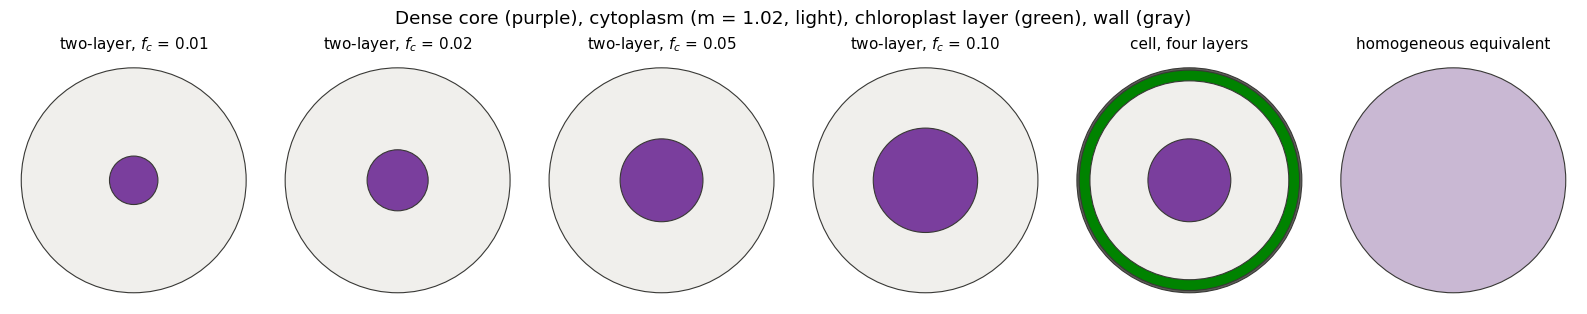

In [4]:
CYT, CORE, CHL, WALL = '#f0efec', '#7a3e9d', '#008300', '#5f5e5a'
fig, axs = plt.subplots(1, 6, figsize=(16, 3.2))
models = [('two-layer, $f_c$ = 0.01', two_layer(1.10, 0.01, 'none', 'layered')[0], [CORE, CYT]),
          ('two-layer, $f_c$ = 0.02', two_layer(1.10, 0.02, 'none', 'layered')[0], [CORE, CYT]),
          ('two-layer, $f_c$ = 0.05', two_layer(1.10, 0.05, 'none', 'layered')[0], [CORE, CYT]),
          ('two-layer, $f_c$ = 0.10', two_layer(1.10, 0.10, 'none', 'layered')[0], [CORE, CYT]),
          ('cell, four layers', cell('nucleus', 'calcite', 'none', 'layered')[0], [CORE, CYT, CHL, WALL]),
          ('homogeneous equivalent', np.array([1.]), ['#c9b8d3'])]
for ax, (title, frac, colors) in zip(axs, models):
    for f, c in zip(frac[::-1], colors[::-1]):
        ax.add_patch(Circle((0, 0), f, facecolor=c, edgecolor='#383835', lw=0.8))
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title)
fig.suptitle('Dense core (purple), cytoplasm (m = 1.02, light), chloroplast layer (green), wall (gray)')
plt.tight_layout()

## 3. Multilayer Mie computations

For each particle, `scattcoeffs` gives the multipole coefficients $a_n, b_n$ of the layered sphere and `scattnlay`
the efficiency factors and asymmetry parameter. The amplitude functions are summed as
$S_1 = \sum_n \frac{2n+1}{n(n+1)} (a_n \pi_n + b_n \tau_n)$ and $S_2 = \sum_n \frac{2n+1}{n(n+1)} (a_n \tau_n + b_n \pi_n)$,
with the angular functions $\pi_n(\cos\theta)$, $\tau_n(\cos\theta)$ tabulated once for all scattering angles.
The scattering matrix elements are normalized as in MOPSMAP: $a_1 = a_2 = 4\langle S_{11}\rangle / \langle x^2 Q_{sca}\rangle$,
$a_3 = a_4 \propto \langle S_{33}\rangle$, $b_1 \propto \langle S_{12}\rangle$, $b_2 \propto -\langle S_{34}\rangle$
(Bohren and Huffman, 1983, with $\int S_{11} d\Omega = \pi x^2 Q_{sca}$). See the companion notebook for details.

In [5]:
NMAX = 1200   # larger than the number of terms needed for x = 842 (1025)


def angular_functions(mu, nmax=NMAX):
    # pi_n and tau_n (n = 0..nmax) at the cosines mu
    pi = np.zeros((nmax + 1, len(mu)))
    tau = np.zeros_like(pi)
    pi[1] = 1.
    for n in range(2, nmax + 1):
        pi[n] = ((2 * n - 1) * mu * pi[n - 1] - n * pi[n - 2]) / (n - 1)
    n = np.arange(1, nmax + 1)[:, None]
    tau[1:] = n * mu * pi[1:] - (n + 1) * pi[:-1]
    return pi, tau


def amplitudes(x_layers, m_layers, pi, tau):
    # S1, S2 of a layered sphere from its multipole coefficients
    terms, an, bn = scattcoeffs(x_layers, m_layers)
    n = np.arange(1, len(an) + 1)
    f = (2 * n + 1) / (n * (n + 1))
    A, B = f * an, f * bn
    P, T = pi[1:len(an) + 1], tau[1:len(an) + 1]
    return A @ P + B @ T, A @ T + B @ P


# check against scattnlay's own amplitude functions for dense-core particles
pi, tau = angular_functions(mu)
for x, frac, m in [(100., [0.46, 1.], [1.20, 1.02 + 0.002j]), (300., [0.46, 0.91, 1.], [1.15, 1.02, 1.10 + 0.01j]),
                   (842., [0.22, 1.], [1.10, 1.02 + 0.003j]),
                   (842., [0.37, 0.89, 0.98, 1.], [1.15, 1.02, 1.10 + 0.01j, 1.19])]:
    X, M = x * np.array(frac), np.array(m, complex)
    S1, S2 = amplitudes(X, M, pi, tau)
    ref = scattnlay(X, M, np.radians(theta))
    err = np.max(np.abs((np.abs(S1) ** 2 + np.abs(S2) ** 2) / (np.abs(ref[8]) ** 2 + np.abs(ref[9]) ** 2) - 1))
    print(f'x = {x:5.0f}, {len(m)} layer(s): max relative difference of S11 = {err:.1e}')

x =   100, 2 layer(s): max relative difference of S11 = 1.8e-14


x =   300, 3 layer(s): max relative difference of S11 = 1.4e-14


x =   842, 2 layer(s): max relative difference of S11 = 7.3e-14


x =   842, 4 layer(s): max relative difference of S11 = 3.7e-14


In [6]:
@dask.delayed
def multilayer_case(frac, m_layers, wl_w, r, mu, weights):
    # size-averaged Qext, ssa, g (psd,) and scattering matrix (psd, theta, element) at one wavelength
    import numpy as np
    from scattnlay import scattnlay

    pi, tau = angular_functions(mu)
    k = 2 * np.pi / wl_w
    qext, qsca, g = (np.empty(len(r)) for _ in range(3))
    S11, S12, S33, S34 = (np.empty((len(r), len(mu))) for _ in range(4))
    for i, ri in enumerate(r):
        X = np.asarray(frac) * k * ri
        out = scattnlay(X, m_layers)
        qext[i], qsca[i], g[i] = out[1], out[2], out[6]
        S1, S2 = amplitudes(X, m_layers, pi, tau)
        S11[i] = (np.abs(S2) ** 2 + np.abs(S1) ** 2) / 2
        S12[i] = (np.abs(S2) ** 2 - np.abs(S1) ** 2) / 2
        S33[i] = np.real(S2 * np.conj(S1))
        S34[i] = np.imag(S2 * np.conj(S1))
    x = k * r
    G = np.pi * r ** 2
    Qext = weights @ (G * qext) / (weights @ G)
    Qsca = weights @ (G * qsca) / (weights @ G)
    gg = weights @ (G * qsca * g) / (weights @ (G * qsca))
    den = (weights @ (x ** 2 * qsca))[:, None] / 4
    a1, a3 = weights @ S11 / den, weights @ S33 / den
    b1, b2 = weights @ S12 / den, -(weights @ S34) / den
    return Qext, Qsca / Qext, gg, np.stack([a1, a1, a3, a3, b1, b2], axis=-1).astype('float32')


structures = ['layered', 'homogeneous']
keys2 = [(s, a, mc, fc) for s in structures for a in absorptions for mc in m_cores for fc in f_cs]
keys3 = [(s, a, o, w) for s in structures for a in absorptions for o in organelles for w in walls]
tasks = []
for key in keys2:
    frac, m = two_layer(key[2], key[3], key[1], key[0])
    tasks += [multilayer_case(frac, m[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
for key in keys3:
    frac, m = cell(key[2], key[3], key[1], key[0])
    tasks += [multilayer_case(frac, m[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
print(len(keys2) + len(keys3), 'particle models,', len(tasks), 'tasks')
t0 = time.perf_counter()
res = dask.compute(*tasks, scheduler='processes', num_workers=os.cpu_count())
print(f'done in {time.perf_counter() - t0:.0f} s')

116 particle models, 1856 tasks


done in 256 s


### Gathering the results

In [7]:
elements = ['a1', 'a2', 'a3', 'a4', 'b1', 'b2']


def gather(res, shape, dims, coords):
    # results ordered as (cases..., wl) with arrays over psd -> Dataset (cases..., wl, psd)
    out = [np.array([x[i] for x in res]) for i in range(4)]
    out = [o.reshape(shape + (len(wl),) + o.shape[1:]) for o in out]
    d = dims + ('wl', 'psd')
    ds = xr.Dataset({'Qext': (d, out[0]), 'ssa': (d, out[1]), 'g': (d, out[2]),
                     'F': (d + ('theta', 'element'), out[3])},
                    coords=dict(coords, wl=wl, psd=psd_ids, theta=theta, element=elements))
    ds = ds.assign_coords(theta_rad=('theta', np.radians(theta)))
    a1 = ds.F.sel(element='a1')
    a1s = a1 * np.sin(ds.theta_rad)
    ds['bb_ratio'] = a1s.where(ds.theta >= 90, drop=True).integrate('theta_rad') / a1s.integrate('theta_rad')
    ds['Qsca'] = ds.Qext * ds.ssa
    ds['Qabs'] = ds.Qext - ds.Qsca
    ds['Qbb'] = ds.Qsca * ds.bb_ratio
    ds['dolp'] = -ds.F.sel(element='b1') / a1
    return ds


n2 = len(keys2) * len(wl)
ds2 = gather(res[:n2], (len(structures), len(absorptions), len(m_cores), len(f_cs)),
             ('structure', 'absorption', 'm_core', 'f_c'),
             dict(structure=structures, absorption=absorptions, m_core=m_cores, f_c=f_cs))
ds2 = ds2.assign_coords(m_eq=(('m_core', 'f_c'), np.outer(m_cores, f_cs) + (1 - np.array(f_cs)) * m_cyt))
ds3 = gather(res[n2:], (len(structures), len(absorptions), len(organelles), len(walls)),
             ('structure', 'absorption', 'organelle', 'wall'),
             dict(structure=structures, absorption=absorptions, organelle=list(organelles), wall=list(walls)))
ds2

<xarray.Dataset> Size: 106MB
Dimensions:     (structure: 2, absorption: 2, m_core: 5, f_c: 4, wl: 16,
                 psd: 8, theta: 369, element: 6)
Coordinates:
  * structure   (structure) <U11 88B 'layered' 'homogeneous'
  * absorption  (absorption) <U7 56B 'none' 'pigment'
  * m_core      (m_core) float64 40B 1.04 1.06 1.1 1.15 1.2
  * f_c         (f_c) float64 32B 0.01 0.02 0.05 0.1
  * wl          (wl) float64 128B 400.0 412.5 442.5 490.0 ... 865.0 885.0 900.0
  * psd         (psd) <U5 160B 'J3.0' 'J3.5' 'J4.0' 'J4.5' ... 'LN1' 'LN2' 'LN5'
  * theta       (theta) float64 3kB 0.0 0.001 0.005 0.01 ... 179.0 179.5 180.0
  * element     (element) <U2 48B 'a1' 'a2' 'a3' 'a4' 'b1' 'b2'
    theta_rad   (theta) float64 3kB 0.0 1.745e-05 8.727e-05 ... 3.133 3.142
    m_eq        (m_core, f_c) float64 160B 1.02 1.02 1.021 ... 1.024 1.029 1.038
Data variables:
    Qext        (structure, absorption, m_core, f_c, wl, psd) float64 82kB 1....
    ssa         (structure, absorption, m_core, f_c, wl, psd) float64 82kB 1....
    g           (structure, absorption, m_core, f_c, wl, psd) float64 82kB 0....
    F           (structure, absorption, m_core, f_c, wl, psd, theta, element) float32 91MB ...
    bb_ratio    (structure, absorption, m_core, f_c, wl, psd) float64 82kB 0....
    Qsca        (structure, absorption, m_core, f_c, wl, psd) float64 82kB 1....
    Qabs        (structure, absorption, m_core, f_c, wl, psd) float64 82kB -1...
    Qbb         (structure, absorption, m_core, f_c, wl, psd) float64 82kB 0....
    dolp        (structure, absorption, m_core, f_c, wl, psd, theta) float32 15MB ...

## 4. Dense-core vs homogeneous particles

### Two-layer particles as a function of the volume-averaged refractive index

Non-absorbing particles at 560 nm. Homogeneous spheres (gray) and dense-core particles (colored by core volume
fraction, one point per $m_{core}$ = 1.04, 1.06, 1.10, 1.15, 1.20) are plotted against the same volume-averaged
refractive index $\bar{m}_r$.

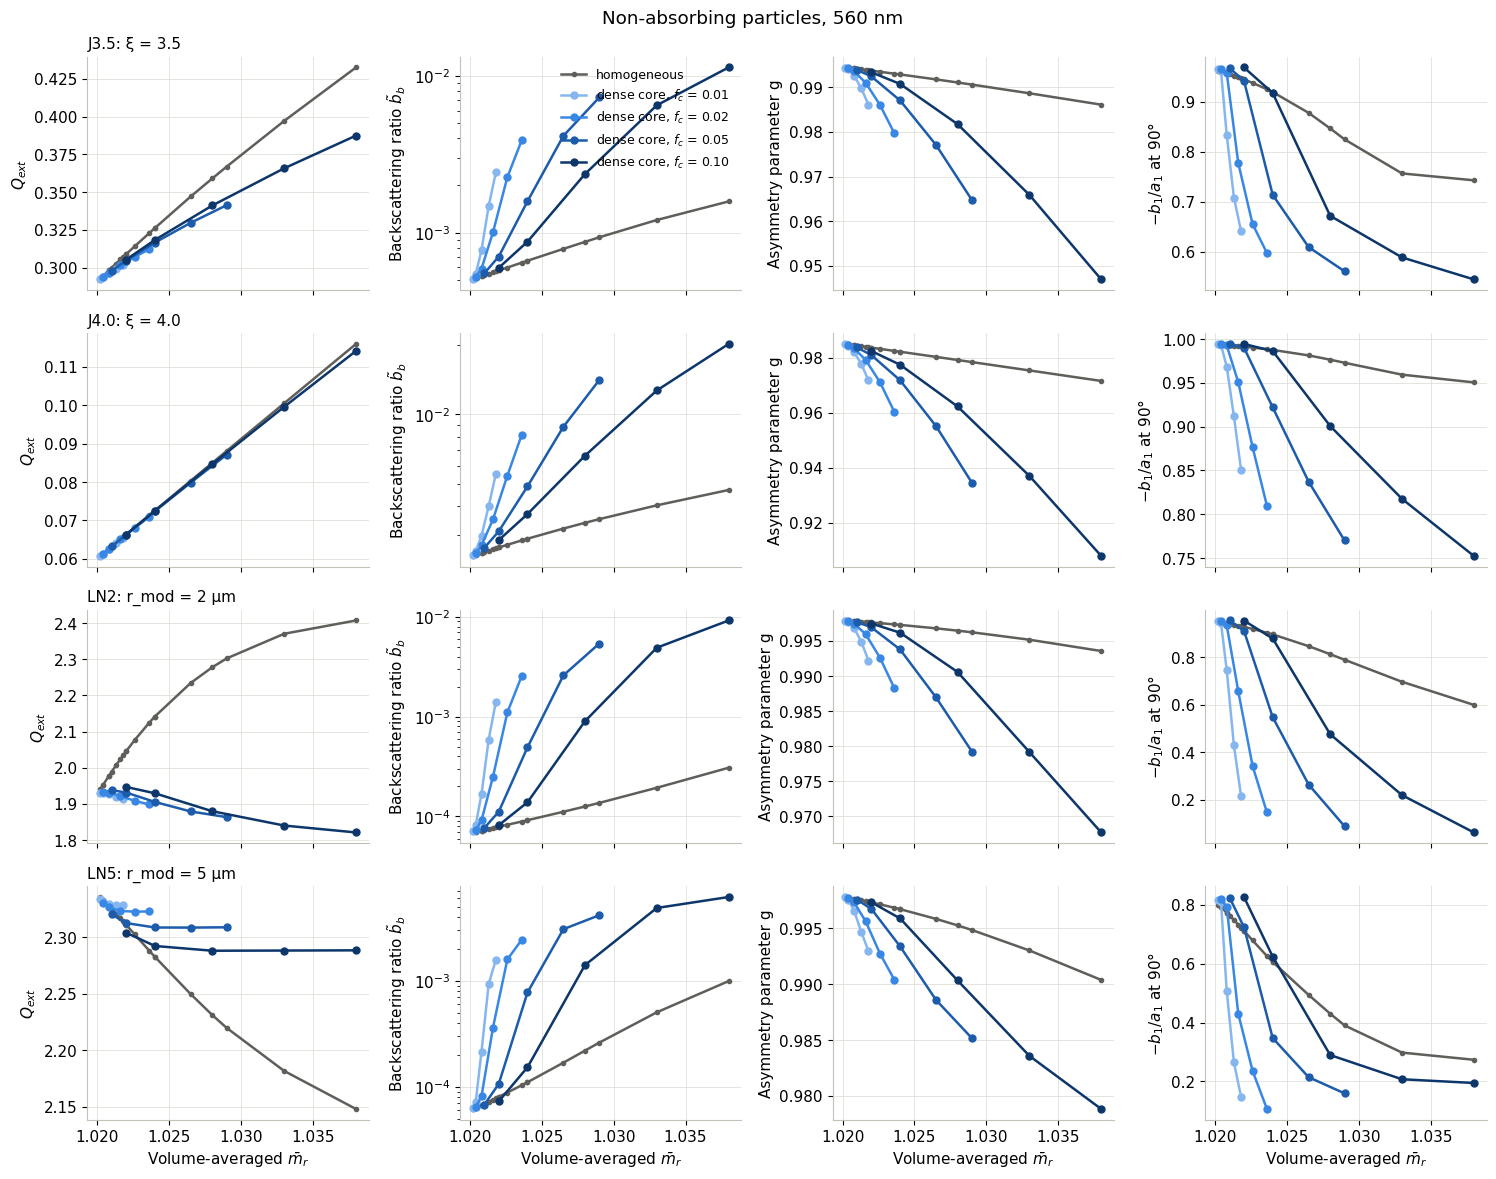

In [8]:
panels = [('Qext', '$Q_{ext}$'), ('bb_ratio', 'Backscattering ratio $\\tilde{b}_b$'), ('g', 'Asymmetry parameter g'),
          ('dolp90', '$-b_1/a_1$ at 90°')]
sub = ds2.sel(absorption='none', wl=560)
sub['dolp90'] = sub.dolp.sel(theta=90)
psds = ['J3.5', 'J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(len(psds), 4, figsize=(15, 3 * len(psds)), sharex=True)
for i, p in enumerate(psds):
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        h = sub[v].sel(structure='homogeneous', psd=p)
        order = np.argsort(sub.m_eq.values.ravel())
        ax.plot(sub.m_eq.values.ravel()[order], h.values.ravel()[order], 'o-', ms=3, color=HOMOG, label='homogeneous')
        for fc, c in zip(f_cs, FV_COLORS):
            lay = sub[v].sel(structure='layered', psd=p, f_c=fc)
            ax.plot(sub.m_eq.sel(f_c=fc), lay, 'o-', ms=5, color=c, label=f'dense core, $f_c$ = {fc:.2f}')
        if v == 'bb_ratio':
            ax.set_yscale('log')
        ax.set_ylabel(label)
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[-1]:
    ax.set_xlabel('Volume-averaged $\\bar{m}_r$')
axs[0, 1].legend(frameon=False)
fig.suptitle('Non-absorbing particles, 560 nm')
plt.tight_layout()

### Ratio of dense-core to homogeneous particles

Range over the eight size distributions at 560 nm (non-absorbing).

In [9]:
sub = ds2.sel(absorption='none', wl=560)
rows = {}
for v in ['Qext', 'bb_ratio', 'g']:
    ratio = sub[v].sel(structure='layered') / sub[v].sel(structure='homogeneous')
    for fc in f_cs:
        rows[(v, f'f_c = {fc:.2f}')] = [f'{float(ratio.sel(m_core=mc, f_c=fc).min()):.2f}–'
                                        f'{float(ratio.sel(m_core=mc, f_c=fc).max()):.2f}' for mc in m_cores]
table = pd.DataFrame(rows, index=[f'm_core = {mc:.2f}' for mc in m_cores]).T
table

m_core = 1.04 m_core = 1.06 m_core = 1.10 m_core = 1.15  \
Qext     f_c = 0.01     0.99–1.00     0.99–1.01     0.97–1.02     0.96–1.03   
         f_c = 0.02     0.99–1.01     0.98–1.02     0.95–1.03     0.92–1.04   
         f_c = 0.05     0.97–1.02     0.94–1.03     0.89–1.06     0.82–1.09   
         f_c = 0.10     0.95–1.03     0.90–1.05     0.83–1.09     0.71–1.14   
bb_ratio f_c = 0.01     1.01–1.03     1.03–1.18     1.09–3.19    1.24–12.89   
         f_c = 0.02     1.01–1.04     1.05–1.26     1.19–4.79    1.45–18.06   
         f_c = 0.05     0.98–1.05     1.13–1.41     1.39–7.04    1.84–23.26   
         f_c = 0.10     0.91–1.08     1.21–1.51     1.57–7.15    2.07–25.33   
g        f_c = 0.01     1.00–1.00     1.00–1.00     1.00–1.00     0.99–1.00   
         f_c = 0.02     1.00–1.00     1.00–1.00     0.99–1.00     0.98–1.00   
         f_c = 0.05     1.00–1.00     0.99–1.00     0.98–1.00     0.96–0.99   
         f_c = 0.10     1.00–1.00     0.99–1.00     0.97–1.00     0.94–0.99   

                    m_core = 1.20  
Qext     f_c = 0.01     0.94–1.03  
         f_c = 0.02     0.88–1.06  
         f_c = 0.05     0.74–1.13  
         f_c = 0.10     0.62–1.17  
bb_ratio f_c = 0.01    1.44–20.29  
         f_c = 0.02    1.79–28.75  
         f_c = 0.05    2.35–39.55  
         f_c = 0.10    2.55–37.10  
g        f_c = 0.01     0.98–1.00  
         f_c = 0.02     0.96–0.99  
         f_c = 0.05     0.93–0.99  
         f_c = 0.10     0.90–0.99

### Backscattering spectra

Backscattering efficiency $Q_{bb}$ of non-absorbing particles with $f_c$ = 0.05 (solid) and of their homogeneous
equivalents (dashed).

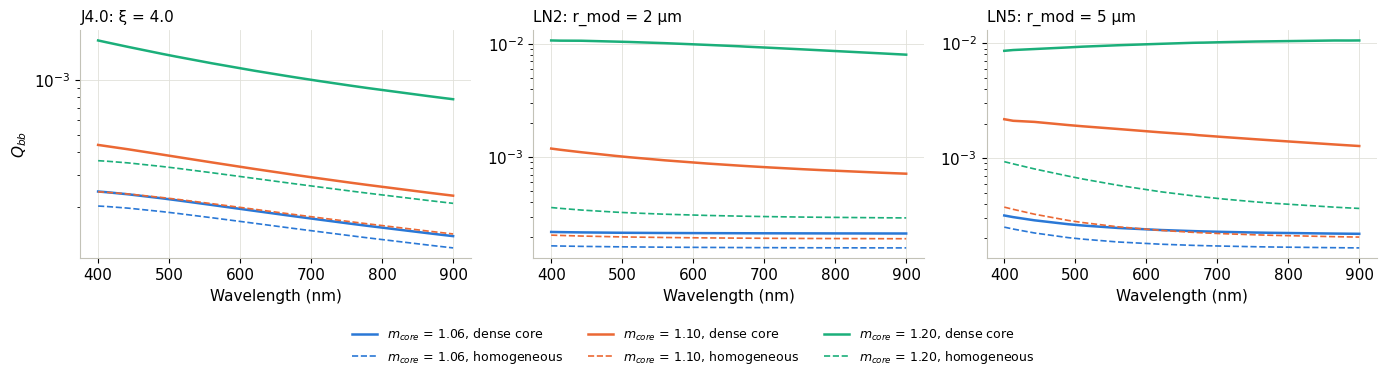

In [10]:
psds = ['J4.0', 'LN2', 'LN5']
colors = dict(zip([1.06, 1.10, 1.20], CAT))
fig, axs = plt.subplots(1, len(psds), figsize=(14, 3.8), sharex=True)
for ax, p in zip(axs, psds):
    for mc, c in colors.items():
        d = ds2.sel(absorption='none', psd=p, f_c=0.05, m_core=mc)
        ax.plot(wl, d.Qbb.sel(structure='layered'), color=c, label=f'$m_{{core}}$ = {mc:.2f}, dense core')
        ax.plot(wl, d.Qbb.sel(structure='homogeneous'), '--', color=c, lw=1.2, label=f'$m_{{core}}$ = {mc:.2f}, homogeneous')
    ax.set_yscale('log')
    ax.set_title(f'{p}: {psd_def[p][1]}', loc='left')
    ax.set_xlabel('Wavelength (nm)')
axs[0].set_ylabel('$Q_{bb}$')
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.14, 1, 1))

### Scattering matrix

Dense-core particles with $f_c$ = 0.05 (solid) and their homogeneous equivalents (dashed), non-absorbing, 560 nm.

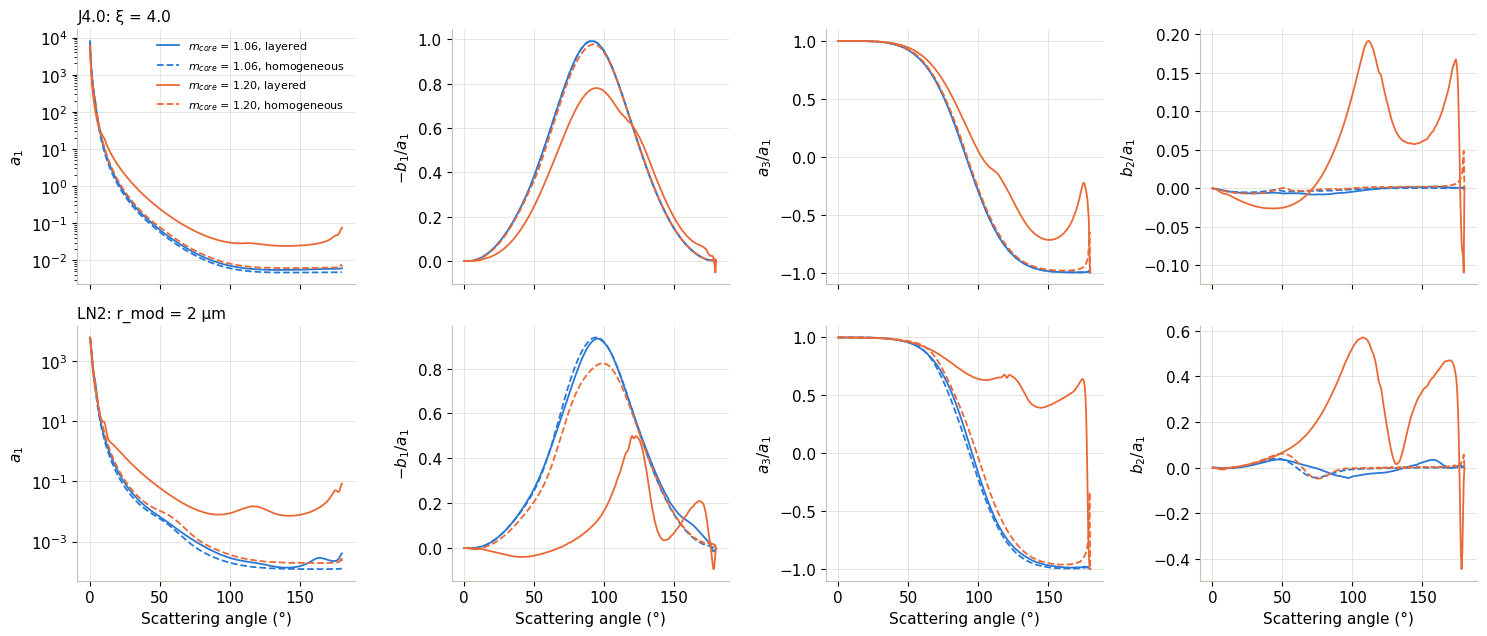

In [11]:
panels = [('a1', '$a_1$'), ('dolp', '$-b_1/a_1$'), ('a3', '$a_3/a_1$'), ('b2', '$b_2/a_1$')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    s = ds2.sel(absorption='none', wl=560, psd=p, f_c=0.05)
    for mc, c in zip([1.06, 1.20], CAT):
        for st, ls in [('layered', '-'), ('homogeneous', '--')]:
            d = s.sel(m_core=mc, structure=st)
            a1 = d.F.sel(element='a1')
            lab = f'$m_{{core}}$ = {mc:.2f}, {st}'
            for j, (v, label) in enumerate(panels):
                y = a1 if v == 'a1' else d.dolp if v == 'dolp' else d.F.sel(element=v) / a1
                axs[i, j].plot(d.theta, y, ls=ls, color=c, lw=1.3, label=lab)
                axs[i, j].set_ylabel(label)
    axs[i, 0].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Scattering angle (°)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Absorption: pigments in the cytoplasm

$Q_{abs}$ of dense-core particles relative to their homogeneous equivalents (same amount of pigment, excluded from
the core), and single scattering albedo, for $m_{core}$ = 1.10.

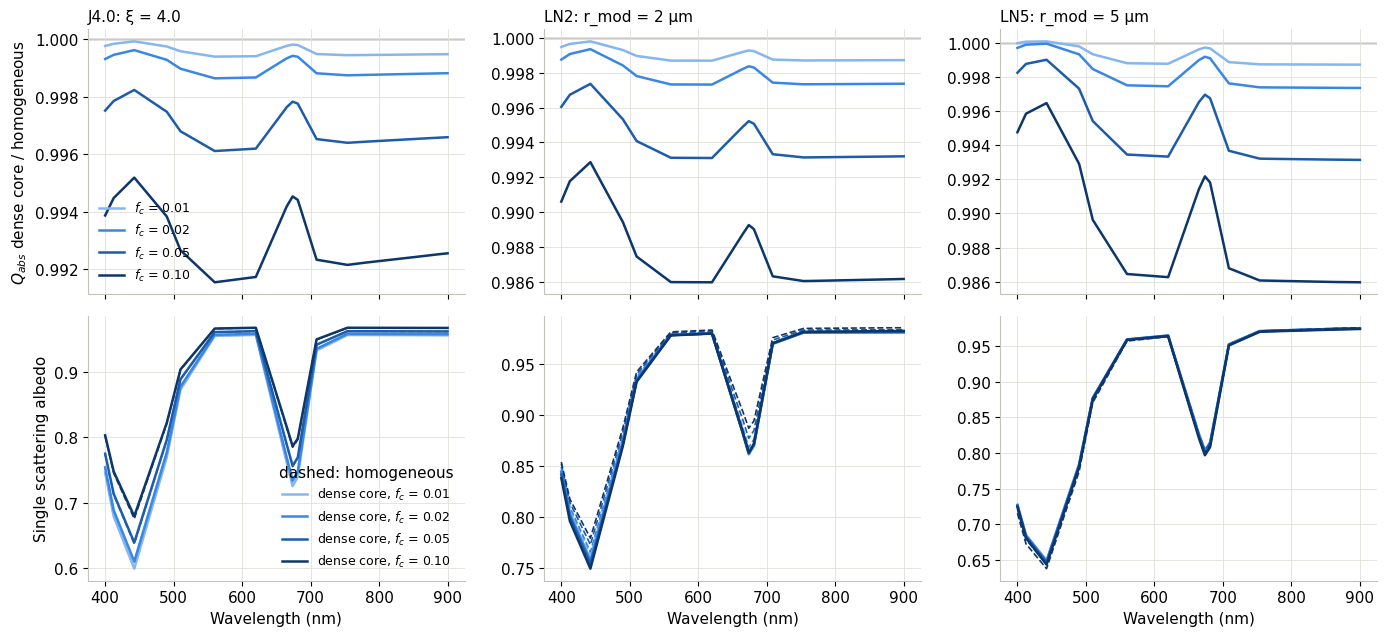

In [12]:
psds = ['J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(2, len(psds), figsize=(14, 6.5), sharex=True)
for j, p in enumerate(psds):
    s = ds2.sel(absorption='pigment', psd=p, m_core=1.10)
    for fc, c in zip(f_cs, FV_COLORS):
        d = s.sel(f_c=fc)
        axs[0, j].plot(wl, d.Qabs.sel(structure='layered') / d.Qabs.sel(structure='homogeneous'), color=c,
                       label=f'$f_c$ = {fc:.2f}')
        axs[1, j].plot(wl, d.ssa.sel(structure='layered'), color=c, label=f'dense core, $f_c$ = {fc:.2f}')
        axs[1, j].plot(wl, d.ssa.sel(structure='homogeneous'), '--', color=c, lw=1.2)
    axs[0, j].axhline(1, color=HOMOG, lw=1, zorder=-1)
    axs[0, j].set_title(f'{p}: {psd_def[p][1]}', loc='left')
    axs[1, j].set_xlabel('Wavelength (nm)')
axs[0, 0].set_ylabel('$Q_{abs}$ dense core / homogeneous')
axs[1, 0].set_ylabel('Single scattering albedo')
axs[0, 0].legend(frameon=False)
axs[1, 0].legend(frameon=False, title='dashed: homogeneous')
plt.tight_layout()

## 5. Cells with organelle core, chloroplast layer and outer wall

### Backscattering spectra

$Q_{bb}$ of cells with pigments in the chloroplast layer, for the three walls (columns) and three cores (colors);
solid: layered cell, dashed: homogeneous equivalent.

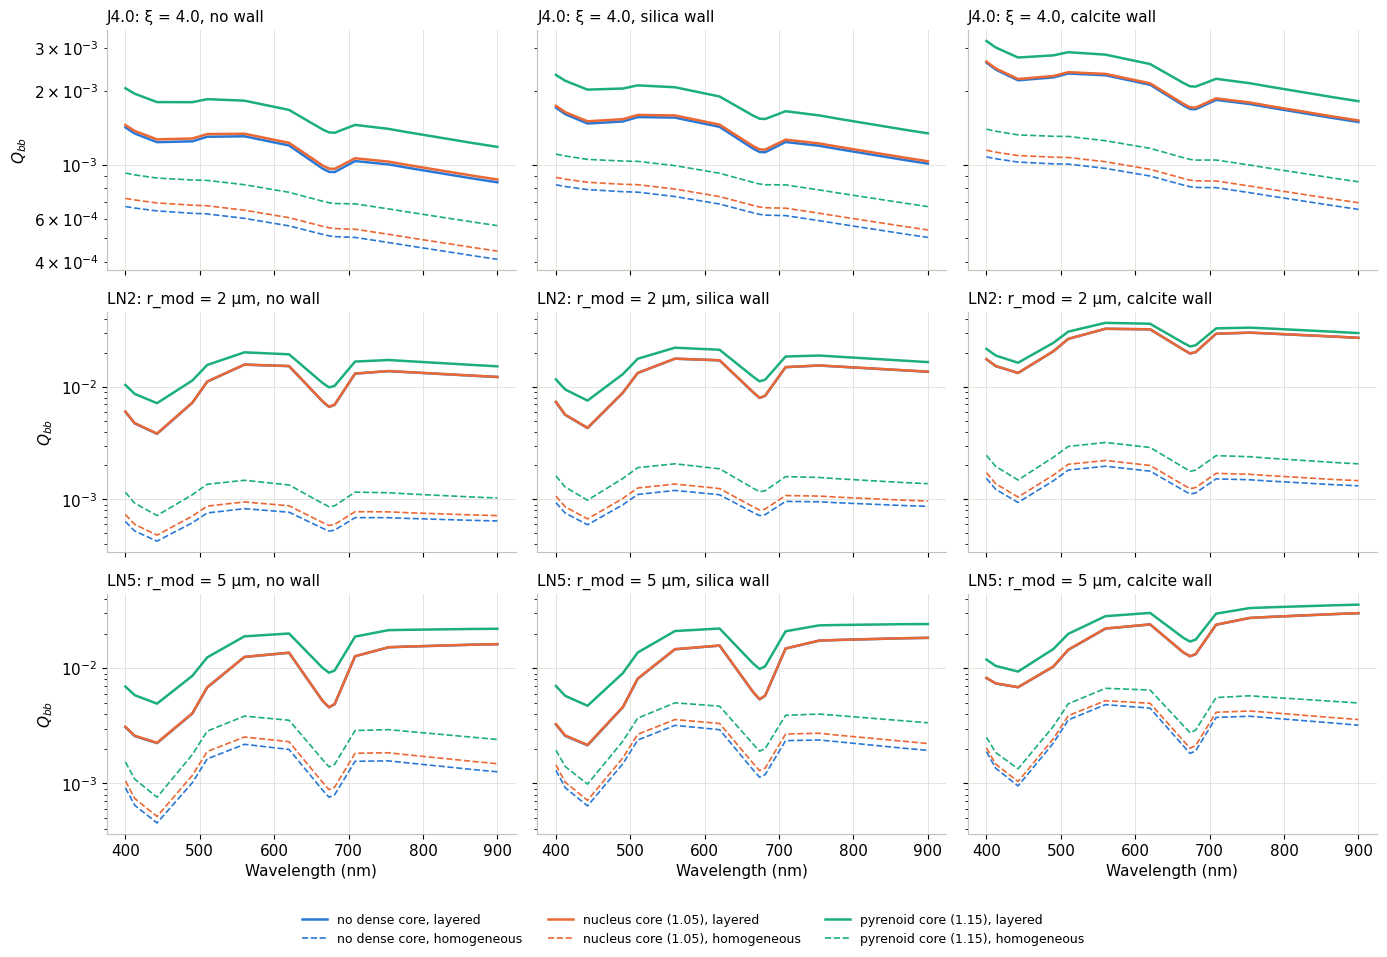

In [13]:
labels = {'none': 'no dense core', 'nucleus': 'nucleus core (1.05)', 'pyrenoid': 'pyrenoid core (1.15)'}
psds = ['J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(len(psds), len(walls), figsize=(14, 3.2 * len(psds)), sharex=True, sharey='row')
for i, p in enumerate(psds):
    for j, wall in enumerate(walls):
        ax = axs[i, j]
        for org, c in zip(organelles, CAT):
            d = ds3.sel(absorption='pigment', psd=p, organelle=org, wall=wall)
            ax.plot(wl, d.Qbb.sel(structure='layered'), color=c, label=f'{labels[org]}, layered')
            ax.plot(wl, d.Qbb.sel(structure='homogeneous'), '--', color=c, lw=1.2, label=f'{labels[org]}, homogeneous')
        ax.set_yscale('log')
        ax.set_title(f'{p}: {psd_def[p][1]}, ' + ('no wall' if wall == 'none' else f'{wall} wall'), loc='left')
    axs[i, 0].set_ylabel('$Q_{bb}$')
for ax in axs[-1]:
    ax.set_xlabel('Wavelength (nm)')
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))

### Respective effects of the core and of the wall

Non-absorbing cells at 560 nm, relative to the cell without dense core and without wall (two-layer chloroplast
model), and backscattering ratio relative to the homogeneous equivalent of each cell.

In [14]:
sub = ds3.sel(absorption='none', wl=560)
ref = sub.sel(organelle='none', wall='none', structure='layered')
rows = {}
for v in ['Qext', 'Qbb', 'bb_ratio']:
    for org in organelles:
        for wall in walls:
            if org == 'none' and wall == 'none':
                continue
            rows[(f'{v} / reference', org, wall)] = (sub[v].sel(organelle=org, wall=wall, structure='layered') / ref[v]).to_pandas()
for org in organelles:
    for wall in walls:
        d = sub.bb_ratio.sel(organelle=org, wall=wall)
        rows[('bb_ratio / homogeneous', org, wall)] = (d.sel(structure='layered') / d.sel(structure='homogeneous')).to_pandas()
table = pd.DataFrame(rows).T.round(2)
table.index.names = ['ratio', 'core', 'wall']
table

psd                                      J3.0  J3.5  J4.0  J4.5  LN0.5    LN1  \
ratio                  core     wall                                            
Qext / reference       none     silica   1.02  1.06  1.10  1.15   1.16   1.07   
                                calcite  1.07  1.15  1.25  1.36   1.36   1.17   
                       nucleus  none     1.01  1.02  1.04  1.06   1.06   1.02   
                                silica   1.02  1.08  1.14  1.21   1.21   1.09   
                                calcite  1.07  1.16  1.29  1.42   1.42   1.18   
                       pyrenoid none     1.03  1.08  1.16  1.28   1.19   1.03   
                                silica   1.04  1.13  1.26  1.43   1.34   1.10   
                                calcite  1.09  1.22  1.41  1.65   1.54   1.18   
Qbb / reference        none     silica   1.11  1.12  1.18  1.22   1.05   1.08   
                                calcite  1.75  1.78  1.74  1.66   1.71   2.10   
                       nucleus  none     1.00  1.01  1.02  1.05   1.00   1.00   
                                silica   1.12  1.13  1.20  1.28   1.06   1.08   
                                calcite  1.76  1.79  1.76  1.71   1.72   2.11   
                       pyrenoid none     1.32  1.31  1.38  1.50   1.20   1.21   
                                silica   1.43  1.43  1.55  1.72   1.25   1.29   
                                calcite  2.06  2.07  2.10  2.14   1.91   2.30   
bb_ratio / reference   none     silica   1.09  1.07  1.07  1.06   0.91   1.00   
                                calcite  1.64  1.55  1.39  1.22   1.26   1.80   
                       nucleus  none     0.99  0.99  0.99  0.99   0.95   0.98   
                                silica   1.09  1.05  1.05  1.05   0.87   0.99   
                                calcite  1.64  1.53  1.37  1.20   1.21   1.78   
                       pyrenoid none     1.28  1.21  1.18  1.17   1.01   1.18   
                                silica   1.38  1.27  1.22  1.20   0.93   1.18   
                                calcite  1.89  1.70  1.49  1.30   1.24   1.95   
bb_ratio / homogeneous none     none     5.57  4.76  2.31  1.30  11.13  16.72   
                                silica   4.95  4.26  2.21  1.31   9.10  13.58   
                                calcite  5.69  4.96  2.51  1.38  10.67  17.65   
                       nucleus  none     5.17  4.41  2.18  1.27  10.18  15.20   
                                silica   4.61  3.98  2.10  1.27   8.37  12.35   
                                calcite  5.45  4.69  2.39  1.34   9.85  16.04   
                       pyrenoid none     5.16  4.42  2.32  1.39   9.42  14.00   
                                silica   4.67  3.97  2.18  1.35   7.76  11.15   
                                calcite  5.28  4.42  2.33  1.37   8.63  13.17   

psd                                        LN2   LN5  
ratio                  core     wall                  
Qext / reference       none     silica    0.98  0.98  
                                calcite   0.99  0.98  
                       nucleus  none      0.99  1.00  
                                silica    0.98  0.98  
                                calcite   0.98  0.98  
                       pyrenoid none      0.97  1.00  
                                silica    0.96  0.98  
                                calcite   0.96  0.98  
Qbb / reference        none     silica    1.08  1.09  
                                calcite   1.89  1.53  
                       nucleus  none      1.00  1.00  
                                silica    1.08  1.09  
                                calcite   1.89  1.54  
                       pyrenoid none      1.24  1.35  
                                silica    1.31  1.45  
                                calcite   2.11  1.88  
bb_ratio / reference   none     silica    1.09  1.11  
                                calcite   1.91  1.56  
                       nucleus  none      1.01  1.00  
         

### Scattering matrix

Non-absorbing cells with a pyrenoid-like core at 560 nm, for the three walls (solid), compared with the cell without
core and wall (black dashed).

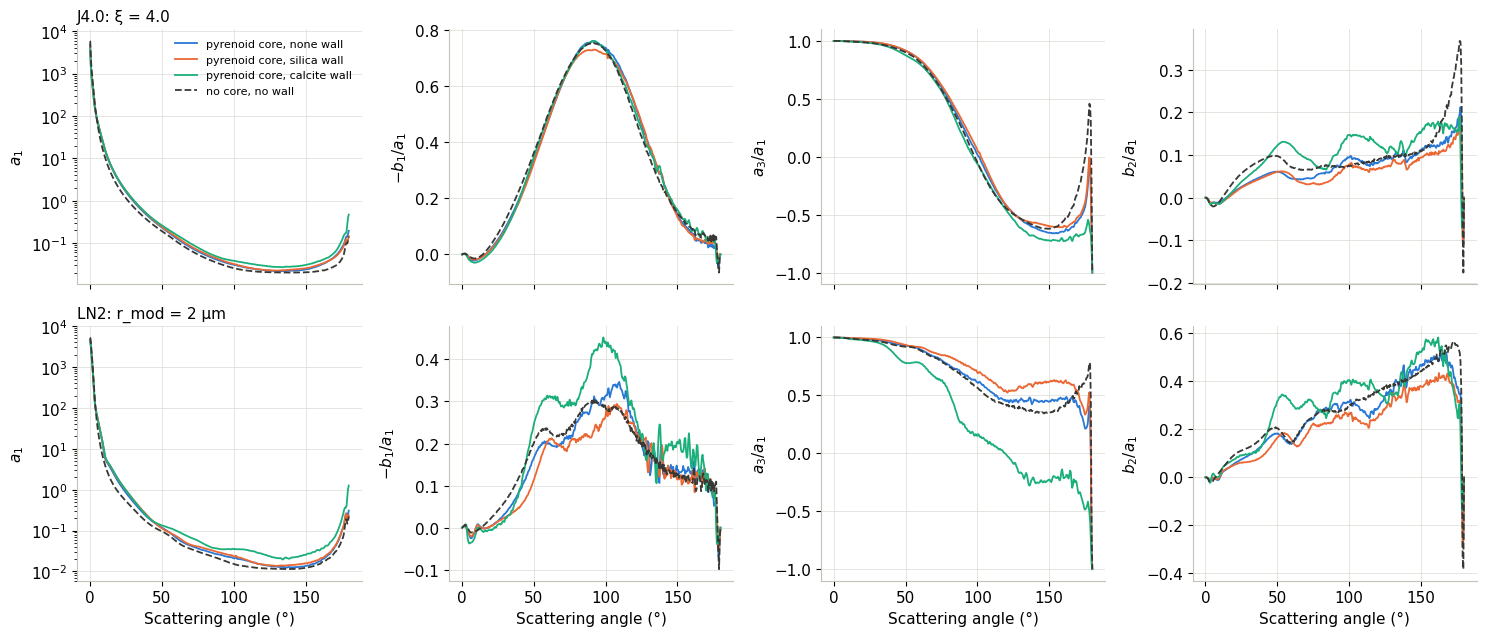

In [15]:
panels = [('a1', '$a_1$'), ('dolp', '$-b_1/a_1$'), ('a3', '$a_3/a_1$'), ('b2', '$b_2/a_1$')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    s = ds3.sel(absorption='none', wl=560, psd=p, structure='layered')
    variants = [(f'pyrenoid core, {w} wall', s.sel(organelle='pyrenoid', wall=w), c, '-') for w, c in zip(walls, CAT)]
    variants.append(('no core, no wall', s.sel(organelle='none', wall='none'), '#383835', '--'))
    for lab, d, c, ls in variants:
        a1 = d.F.sel(element='a1')
        for j, (v, label) in enumerate(panels):
            y = a1 if v == 'a1' else d.dolp if v == 'dolp' else d.F.sel(element=v) / a1
            axs[i, j].plot(d.theta, y, ls=ls, color=c, lw=1.3, label=lab)
            axs[i, j].set_ylabel(label)
    axs[i, 0].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Scattering angle (°)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## Main results

Layered particles are compared with homogeneous spheres of the same size and the same volume-averaged
refractive index $\bar{m}_r$ (all OLCI bands and the eight size distributions, unless stated otherwise).

**Small dense cores (two-layer)**

* **Even a small core increases backscattering, as soon as its index differs enough from the cytoplasm.** For a
  core of 1 % of the volume (22 % of the radius), the backscattering ratio $\tilde{b}_b$ relative to the
  homogeneous equivalent is ×1.0–1.2 for a nucleus-like core ($m_{core}$ = 1.06), ×1.1–3.3 for $m_{core}$ = 1.10
  and up to ×13–22 for $m_{core}$ = 1.15–1.20. With 10 % of the volume, these factors reach ×1.2–1.5, ×1.5–8 and
  ×26–40. A core of $m_{core}$ = 1.04 has almost no effect (×0.8–1.1).
* **At a given volume-averaged index, the smaller the core, the larger the backscattering**: the same amount of
  dense material concentrated in a smaller, higher-index core is more efficient than in a larger, lower-index one.
  The enhancement is largest for the log-normal distributions and smallest for the steep Junge distributions
  (J4.0, J4.5: ×1.0–2.3 for $f_c$ = 0.01, up to ×4.9 for $f_c$ = 0.10).
* **$Q_{ext}$ and $g$ change little for the smallest cores** ($f_c$ = 0.01: $Q_{ext}$ ×0.94–1.03, $g$ ≥ 0.98 times
  the homogeneous value), but $Q_{ext}$ drops to 0.62 for $f_c$ = 0.10 and $m_{core}$ = 1.20. The polarized elements
  ($-b_1/a_1$ at 90°, $a_3/a_1$, $b_2/a_1$) depart from the homogeneous sphere for $m_{core} \geq$ 1.15.
* **Absorption is almost unchanged** when the pigment is only excluded from the core ($Q_{abs}$ ×0.97–1.01); the
  single scattering albedo changes by −0.07 to +0.04 in the blue, through the change in scattering.

**Cells with core, chloroplast layer and wall (up to four layers)**

The reference is the two-layer chloroplast cell (no dense core, no wall). For non-absorbing cells:

* a **nucleus-like core** (1.05, 5 % of the volume) is invisible behind the chloroplast layer ($Q_{bb}$ ×1.00–1.06),
* a **pyrenoid-like core** (1.15) increases $Q_{bb}$ by ×1.2–1.5,
* a **silica wall** increases $Q_{bb}$ by ×1.05–1.23 and a **calcite wall** by ×1.5–2.1,
* their effects combine but slightly less than multiplicatively: pyrenoid core + calcite wall gives ×1.8–2.3,
  about 10 % less than the product of the separate effects,
* the wall and the core both increase $Q_{ext}$ of the small particles (up to ×1.65 for J4.5 with pyrenoid core and
  calcite wall), and the calcite wall strongly modifies $a_3/a_1$ and $-b_1/a_1$ of the larger cells (LN2).

With pigments, the $Q_{bb}$ factors are larger in the absorption bands (up to ×4.3 for pyrenoid core + calcite
wall), because the high-index core and wall do not absorb. All cells keep a backscattering ratio 1.2–20 times that
of their homogeneous equivalent: the homogeneous-sphere model misses most of the backscattering of structured cells,
whatever the details of the core and the wall.

These results are for idealized concentric spheres. Real organelles are off-centered, non-spherical and
numerous, which smooths the angular features; the multilayer results indicate the sensitivity to the internal
structure rather than a model of a given species.

## 6. Saving the results

In [16]:
ofile = odir / 'sensitivity_core_particles.nc'
attrs = dict(refractive_index='relative to seawater, n_w = 1.34', wavelength='OLCI bands in vacuum (nm)',
             radius_range_um=f'{r_min}-{r_max}', method='multilayer Mie theory (scattnlay)')
ds2.drop_vars('theta_rad').assign_attrs(attrs, model='two-layer: dense core + cytoplasm m=1.02').to_netcdf(
    ofile, group='two_layer', encoding={'F': {'zlib': True, 'complevel': 4}})
ds3.drop_vars('theta_rad').assign_attrs(attrs, model='cells: organelle core, cytoplasm, chloroplast, wall').to_netcdf(
    ofile, group='cells', mode='a', encoding={'F': {'zlib': True, 'complevel': 4}})
print(ofile, f'{ofile.stat().st_size / 1e6:.1f} MB')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/mopsmap_tbx/scatmat/sensitivity/sensitivity_core_particles.nc 113.4 MB
